# SmartAir — Corrected ANN/MLP AQI Forecasting Project

**Goal:** Predict a station's AQI for the next day using the previous 7 consecutive days of pollutant readings and historical AQI.

- Dataset: `rohanrao/air-quality-data-in-india`, file `station_day.csv`
- Problem type: supervised regression
- Model family: feed-forward Artificial Neural Network (MLP)
- Target: `AQI`
- `AQI_Bucket` is deliberately excluded because it is derived from AQI and would leak target information.
- The chronological split is based on dates. Because stations have different gaps and coverage, the resulting *sample* proportions may not be exactly 70/15/15; the notebook reports the actual counts and percentages rather than mislabeling them.

Run this notebook from top to bottom in Google Colab. The first cell installs dependencies. KaggleHub may prompt for Kaggle authentication depending on your environment.

In [6]:
# 1. Install dependencies (Google Colab / fresh Python environment)
!pip -q install kagglehub tensorflow scikit-learn seaborn joblib

In [7]:
# 2. Imports and reproducibility
import os
import random
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: True


## 1. Load the dataset

In [8]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

DATASET_HANDLE = "rohanrao/air-quality-data-in-india"
FILE_PATH = "station_day.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    DATASET_HANDLE,
    FILE_PATH
)

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

if len(df) < 50_000:
    raise ValueError(f"Assignment requires at least 50,000 records; found {len(df):,}.")
print(f"PASS: {len(df):,} records (50,000+ requirement met).")

100%|██████████| 2.52M/2.52M [00:00<00:00, 123MB/s]

Extracting zip of station_day.csv...


Dataset shape: (108035, 16)


,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,AP001,2017-11-24,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92,0.10,NaN,NaN
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,0.06,184.0,Moderate
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,0.08,197.0,Moderate
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,0.12,198.0,Moderate
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,0.07,188.0,Moderate



Columns: ['StationId', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']
PASS: 108,035 records (50,000+ requirement met).


## 2. Initial data understanding and EDA

In [9]:
print("DATASET INFORMATION")
df.info()

print("\nSTATISTICAL SUMMARY")
display(df.describe(include="all").T)

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Percentage", ascending=False)
display(missing_summary)

print("Duplicate full rows:", df.duplicated().sum())
print("Unique stations:", df["StationId"].nunique())
print("Raw date range:", df["Date"].min(), "to", df["Date"].max())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108035 entries, 0 to 108034
Data columns (total 16 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   StationId   108035 non-null  object 
 1   Date        108035 non-null  object 
 2   PM2.5       86410 non-null   float64
 3   PM10        65329 non-null   float64
 4   NO          90929 non-null   float64
 5   NO2         91488 non-null   float64
 6   NOx         92535 non-null   float64
 7   NH3         59930 non-null   float64
 8   CO          95037 non-null   float64
 9   SO2         82831 non-null   float64
 10  O3          82467 non-null   float64
 11  Benzene     76580 non-null   float64
 12  Toluene     69333 non-null   float64
 13  Xylene      22898 non-null   float64
 14  AQI         87025 non-null   float64
 15  AQI_Bucket  87025 non-null   object 
dtypes: float64(13), object(3)
memory usage: 13.2+ MB

STATISTICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
StationId,108035,110,DL007,2009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,108035,2009,2020-06-17,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM2.5,86410.0,NaN,NaN,NaN,80.272571,76.526403,0.02,31.88,55.95,99.92,1000.0
PM10,65329.0,NaN,NaN,NaN,157.968427,123.418672,0.01,70.15,122.09,208.67,1000.0
NO,90929.0,NaN,NaN,NaN,23.123424,34.491019,0.01,4.84,10.29,24.98,470.0
NO2,91488.0,NaN,NaN,NaN,35.24076,29.510827,0.01,15.09,27.21,46.93,448.05
NOx,92535.0,NaN,NaN,NaN,41.195055,45.145976,0.0,13.97,26.66,50.5,467.63
NH3,59930.0,NaN,NaN,NaN,28.732875,24.897797,0.01,11.9,23.59,38.1375,418.9
CO,95037.0,NaN,NaN,NaN,1.605749,4.369578,0.0,0.53,0.91,1.45,175.81
SO2,82831.0,NaN,NaN,NaN,12.257634,12.984723,0.01,5.04,8.95,14.92,195.65


,Missing Count,Missing Percentage
Xylene,85137,78.81
NH3,48105,44.53
PM10,42706,39.53
Toluene,38702,35.82
Benzene,31455,29.12
O3,25568,23.67
SO2,25204,23.33
PM2.5,21625,20.02
AQI_Bucket,21010,19.45
AQI,21010,19.45


Duplicate full rows: 0
Unique stations: 110
Raw date range: 2015-01-01 to 2020-07-01


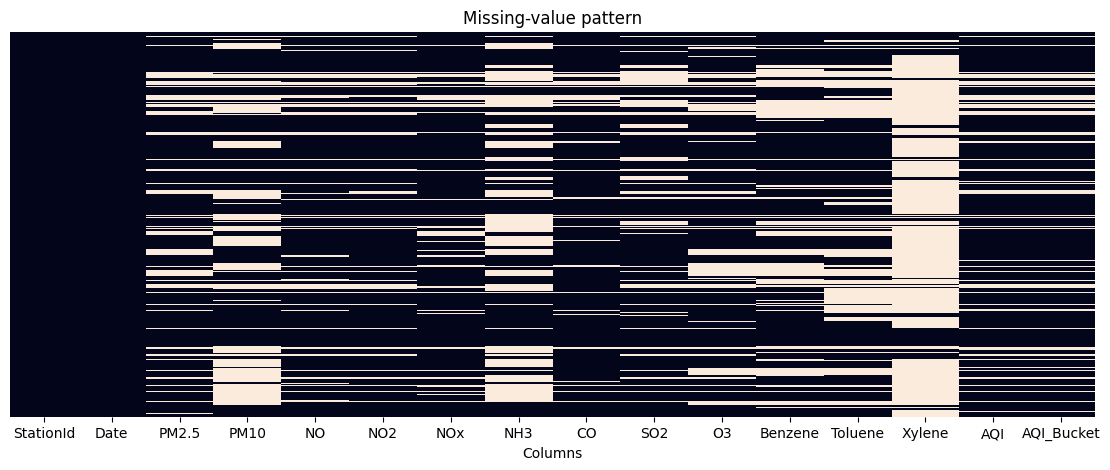

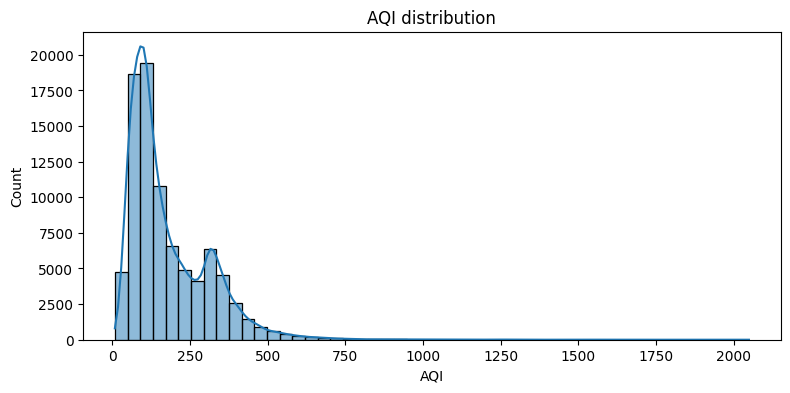

In [10]:
plt.figure(figsize=(14, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Missing-value pattern")
plt.xlabel("Columns")
plt.show()

plt.figure(figsize=(9, 4))
sns.histplot(pd.to_numeric(df["AQI"], errors="coerce").dropna(), bins=50, kde=True)
plt.title("AQI distribution")
plt.xlabel("AQI")
plt.show()

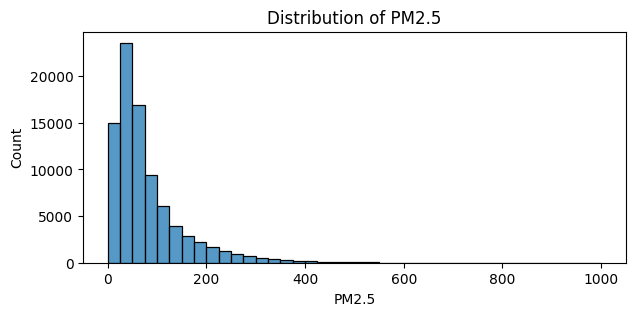

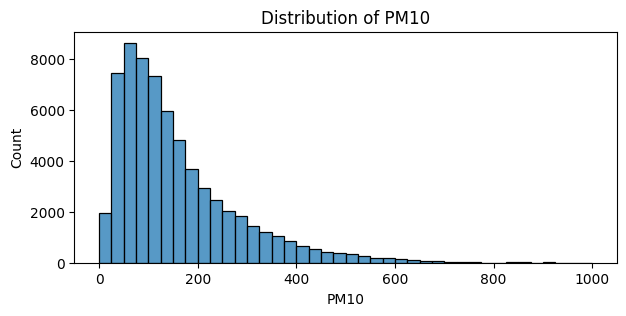

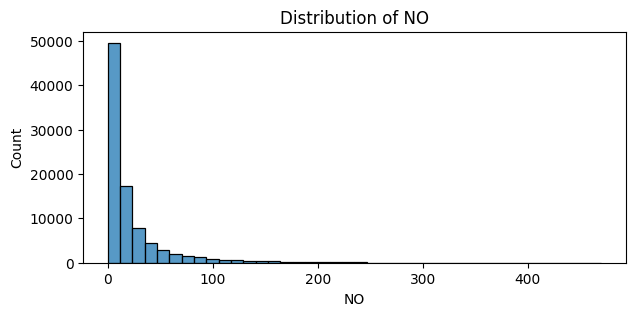

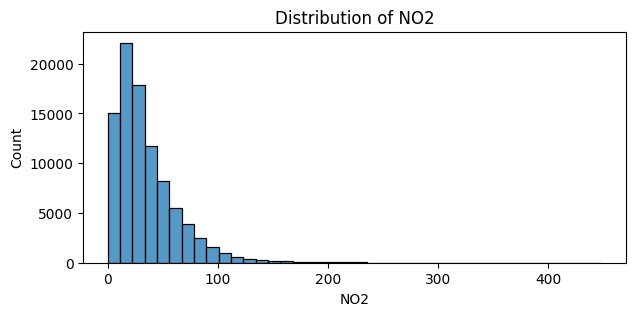

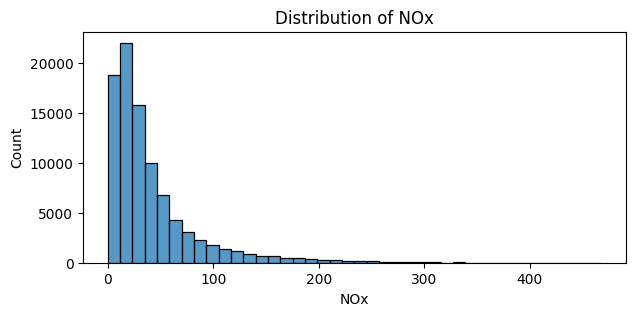

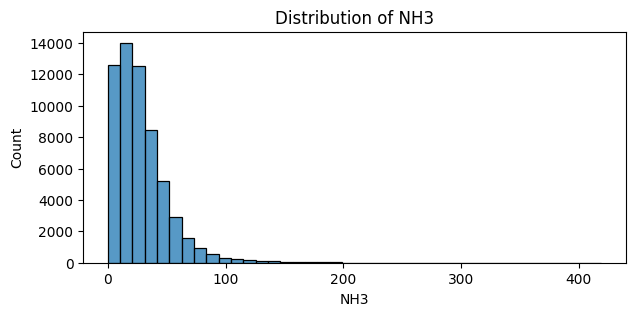

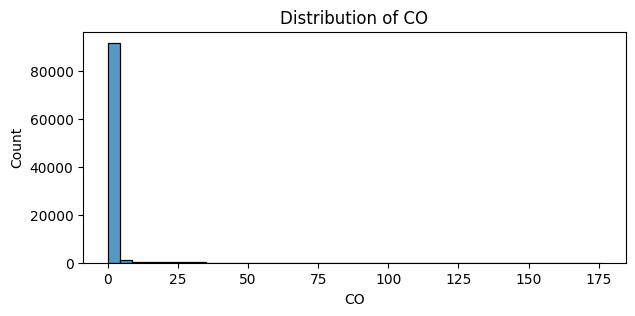

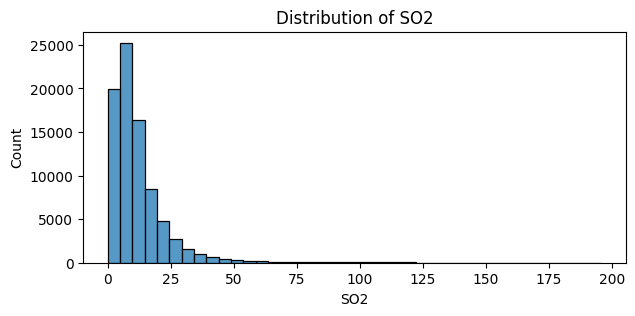

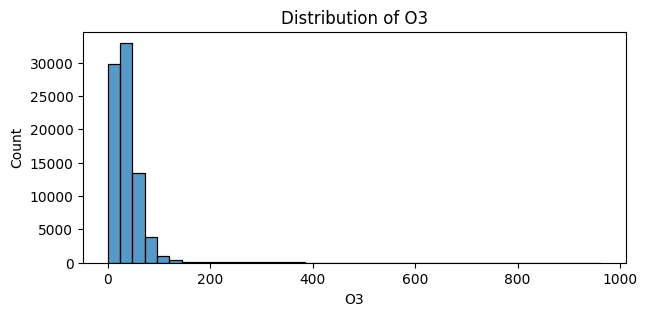

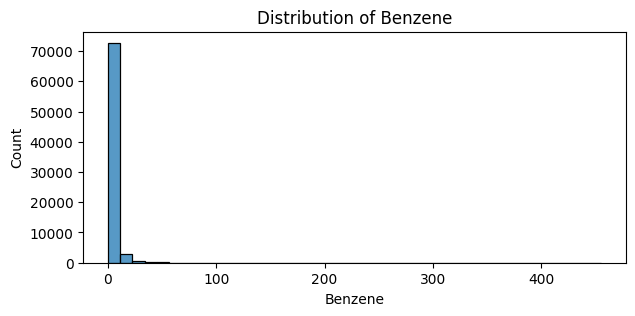

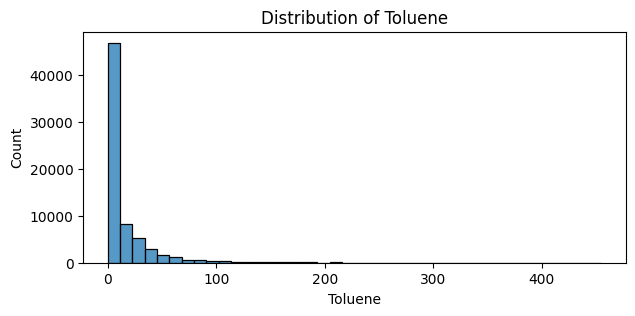

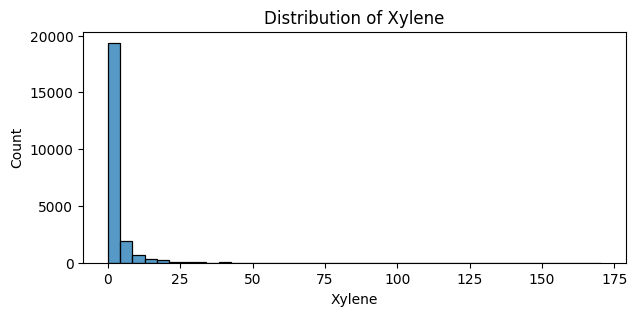

In [11]:
POLLUTANTS = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]
available_pollutants = [c for c in POLLUTANTS if c in df.columns]

for col in available_pollutants:
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    if values.empty:
        continue
    plt.figure(figsize=(7, 3))
    sns.histplot(values, bins=40, kde=False)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.show()

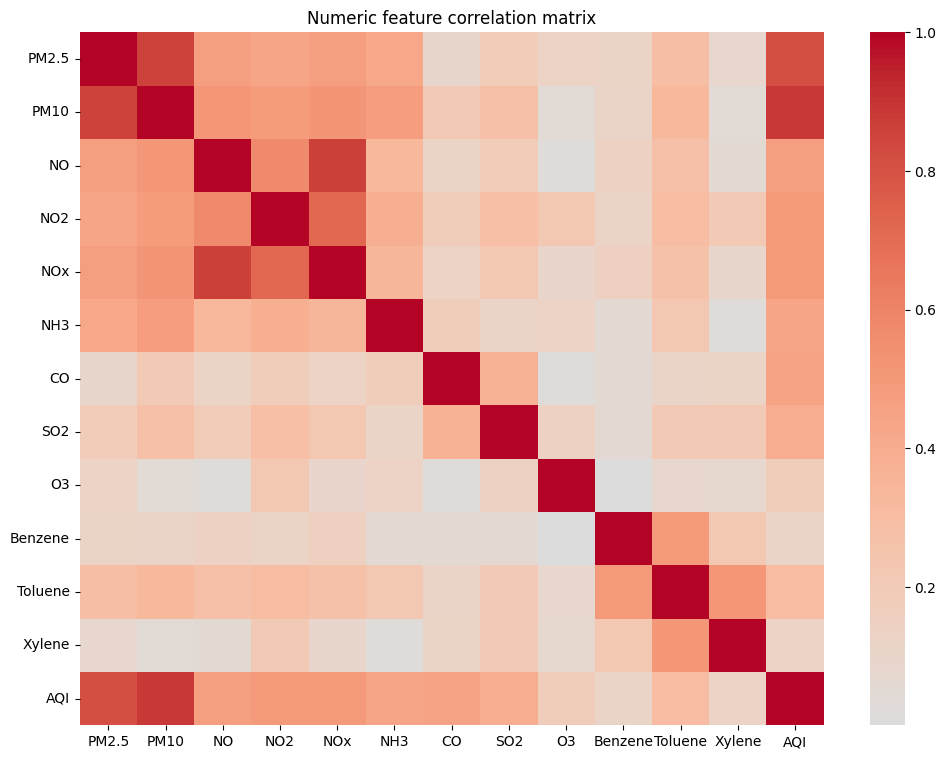

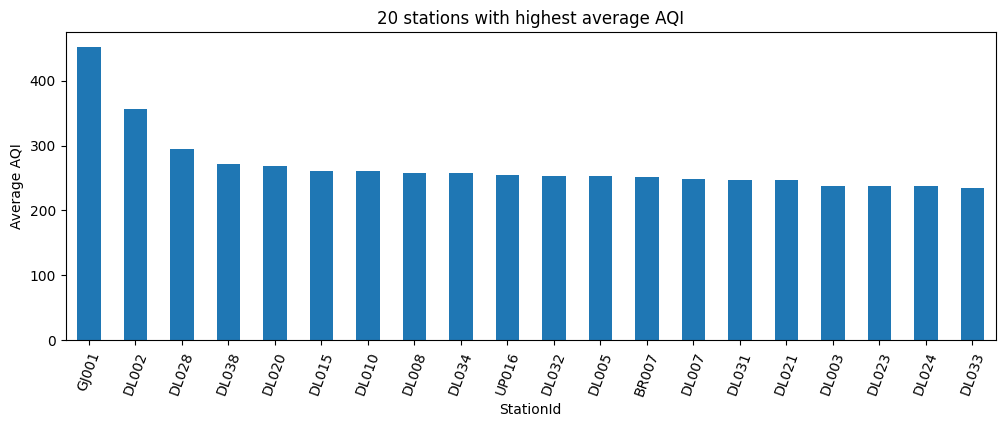

In [12]:
numeric_eda = df.select_dtypes(include=np.number)
plt.figure(figsize=(12, 9))
sns.heatmap(numeric_eda.corr(), cmap="coolwarm", center=0)
plt.title("Numeric feature correlation matrix")
plt.show()

station_mean_aqi = df.groupby("StationId")["AQI"].mean().dropna().sort_values(ascending=False)
plt.figure(figsize=(12, 4))
station_mean_aqi.head(20).plot(kind="bar")
plt.title("20 stations with highest average AQI")
plt.ylabel("Average AQI")
plt.xticks(rotation=70)
plt.show()

In [13]:
# IQR is used to FLAG potential outliers, not automatically delete them.
# Very high AQI/pollutant values can represent genuine pollution episodes.
outlier_rows = []
for col in available_pollutants + ["AQI"]:
    if col not in df.columns:
        continue
    x = pd.to_numeric(df[col], errors="coerce").dropna()
    if len(x) == 0:
        continue
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((x < lo) | (x > hi)).sum())
    outlier_rows.append({
        "Feature": col, "Outlier Count": n_out,
        "Outlier Percentage": round(100 * n_out / len(x), 2),
        "IQR Lower": lo, "IQR Upper": hi,
        "Observed Min": x.min(), "Observed Max": x.max()
    })
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

,Feature,Outlier Count,Outlier Percentage,IQR Lower,IQR Upper,Observed Min,Observed Max
0,PM2.5,6448,7.46,-70.18000,201.98000,0.02,1000.00
1,PM10,3084,4.72,-137.63000,416.45000,0.01,1000.00
2,NO,9869,10.85,-25.37000,55.19000,0.01,470.00
3,NO2,3786,4.14,-32.67000,94.69000,0.01,448.05
4,NOx,7604,8.22,-40.82500,105.29500,0.00,467.63
5,NH3,2241,3.74,-27.45625,77.49375,0.01,418.90
6,CO,6460,6.80,-0.85000,2.83000,0.00,175.81
7,SO2,5067,6.12,-9.78000,29.74000,0.01,195.65
8,O3,2985,3.62,-23.47250,89.50750,0.01,963.00
9,Benzene,5987,7.82,-5.01500,8.78500,0.00,455.03


## 3. Clean the data

In [14]:
data = df.copy()
data.columns = data.columns.str.strip()

required = ["StationId", "Date", "AQI"]
missing_required = [c for c in required if c not in data.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
data["AQI"] = pd.to_numeric(data["AQI"], errors="coerce")

for col in available_pollutants:
    data[col] = pd.to_numeric(data[col], errors="coerce")

before = len(data)
data = data.dropna(subset=["StationId", "Date", "AQI"]).copy()
data = data[data["AQI"] >= 0].copy()
data = data.sort_values(["StationId", "Date"])
duplicate_station_dates = int(data.duplicated(["StationId", "Date"]).sum())
data = data.drop_duplicates(["StationId", "Date"], keep="first")
data = data.sort_values(["StationId", "Date"]).reset_index(drop=True)

print(f"Rows before cleaning: {before:,}")
print(f"Rows after cleaning:  {len(data):,}")
print(f"Rows removed:         {before - len(data):,}")
print(f"Duplicate station-date rows removed: {duplicate_station_dates:,}")
print("Stations:", data["StationId"].nunique())
print("Date range:", data["Date"].min().date(), "to", data["Date"].max().date())
print("\nRemaining missing values:")
display(data.isna().sum().sort_values(ascending=False).to_frame("Missing Count"))

Rows before cleaning: 108,035
Rows after cleaning:  87,025
Rows removed:         21,010
Duplicate station-date rows removed: 0
Stations: 109
Date range: 2015-01-01 to 2020-07-01

Remaining missing values:


,Missing Count
Xylene,67584
NH3,29832
Toluene,26324
PM10,23961
Benzene,19787
O3,9598
SO2,9533
NOx,4555
PM2.5,3488
CO,2896


## 4. Chronological train / validation / test split

The split is based on unique calendar dates, not random rows. This prevents future target dates from being placed in training. We use 70% of dates for training, the next 15% for validation, and the final 15% for testing.

**Important:** after requiring 7 consecutive historical days for every station, the number of valid forecasting samples in each split can differ from 70/15/15. The actual sample counts are printed after sequence creation.

In [15]:
unique_dates = np.array(sorted(data["Date"].dropna().unique()))
if len(unique_dates) < 20:
    raise ValueError("Not enough unique dates to create meaningful chronological splits.")

n_dates = len(unique_dates)
train_cut = max(1, int(n_dates * 0.70))
val_cut = max(train_cut + 1, int(n_dates * 0.85))
val_cut = min(val_cut, n_dates - 1)

train_end_date = pd.Timestamp(unique_dates[train_cut - 1])
val_end_date = pd.Timestamp(unique_dates[val_cut - 1])
test_end_date = pd.Timestamp(unique_dates[-1])

print(f"Training target dates:   through {train_end_date.date()}")
print(f"Validation target dates: {train_end_date.date()} to {val_end_date.date()}")
print(f"Test target dates:       after {val_end_date.date()} to {test_end_date.date()}")
print(f"Unique dates: {n_dates:,}")

Training target dates:   through 2018-11-06
Validation target dates: 2018-11-06 to 2019-09-03
Test target dates:       after 2019-09-03 to 2020-07-01
Unique dates: 2,009


## 5. Feature preparation without fitting preprocessing on future data

- Pollutant columns with more than 60% missing values **in the training period** are excluded. This prevents a feature such as Xylene (which is very sparse in this dataset) from being mostly fabricated by imputation.
- Remaining missing numeric values are median-imputed using training-period rows only.
- Numeric inputs are standardized using training-period rows only.
- Station one-hot columns are learned from training stations only. A station not seen during training receives all-zero station indicators.
- Calendar features are deterministic transformations of the date.

In [16]:
LOOKBACK = 7
MAX_MISSING_FRACTION = 0.60

data["DayOfYear"] = data["Date"].dt.dayofyear
data["Day_Sin"] = np.sin(2 * np.pi * data["DayOfYear"] / 365.25)
data["Day_Cos"] = np.cos(2 * np.pi * data["DayOfYear"] / 365.25)
data["Month_Sin"] = np.sin(2 * np.pi * data["Date"].dt.month / 12.0)
data["Month_Cos"] = np.cos(2 * np.pi * data["Date"].dt.month / 12.0)

time_features = ["Day_Sin", "Day_Cos", "Month_Sin", "Month_Cos"]
candidate_numeric = [c for c in available_pollutants if c in data.columns] + ["AQI"] + time_features

training_rows_mask = data["Date"] <= train_end_date
training_missing_fraction = data.loc[training_rows_mask, candidate_numeric].isna().mean()

selected_pollutants = [
    c for c in available_pollutants
    if training_missing_fraction.get(c, 1.0) <= MAX_MISSING_FRACTION
]
excluded_pollutants = [
    c for c in available_pollutants if c not in selected_pollutants
]

numeric_features = selected_pollutants + ["AQI"] + time_features

print("Selected pollutant features:", selected_pollutants)
print("Excluded due to >60% training-period missingness:", excluded_pollutants)
print("\nTraining-period missingness (%):")
display((training_missing_fraction * 100).round(2).to_frame("Missing %"))

# Fit imputer and scaler ONLY on training-period rows.
imputer = SimpleImputer(strategy="median")
imputer.fit(data.loc[training_rows_mask, numeric_features])

numeric_imputed = imputer.transform(data[numeric_features])
if numeric_imputed.shape[1] != len(numeric_features):
    raise ValueError("The imputer changed the feature count. Check for all-missing training columns.")

scaler = StandardScaler()
scaler.fit(numeric_imputed[training_rows_mask.to_numpy()])
numeric_scaled = scaler.transform(numeric_imputed)

# Learn station categories from training period only.
train_stations = sorted(data.loc[training_rows_mask, "StationId"].astype(str).unique())
station_to_index = {station: i for i, station in enumerate(train_stations)}
station_codes = data["StationId"].astype(str).map(station_to_index)

station_matrix = np.zeros((len(data), len(train_stations)), dtype=np.float32)
known_station_mask = station_codes.notna().to_numpy()
station_matrix[np.where(known_station_mask)[0], station_codes[known_station_mask].astype(int).to_numpy()] = 1.0

feature_matrix = np.concatenate(
    [numeric_scaled.astype(np.float32), station_matrix],
    axis=1
)
feature_names = numeric_features + [f"Station_{s}" for s in train_stations]

print("Feature matrix:", feature_matrix.shape)
print("Total features:", len(feature_names))

Selected pollutant features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
Excluded due to >60% training-period missingness: ['Xylene']

Training-period missingness (%):


,Missing %
PM2.5,5.65
PM10,40.68
NO,3.03
NO2,2.49
NOx,9.27
NH3,45.14
CO,6.11
SO2,11.79
O3,15.94
Benzene,26.45


Feature matrix: (87025, 91)
Total features: 91


## 6. Build 7-day sequences and split by the target date

In [17]:
X_parts = {"train": [], "validation": [], "test": []}
y_parts = {"train": [], "validation": [], "test": []}
persistence_parts = {"train": [], "validation": [], "test": []}
date_parts = {"train": [], "validation": [], "test": []}
station_parts = {"train": [], "validation": [], "test": []}

station_values = data["StationId"].astype(str).to_numpy()
date_values = data["Date"].to_numpy()
aqi_values = data["AQI"].to_numpy()

for station in data["StationId"].astype(str).unique():
    idx = np.where(station_values == station)[0]
    idx = idx[np.argsort(date_values[idx])]

    for pos in range(LOOKBACK, len(idx)):
        window_idx = idx[pos - LOOKBACK:pos]
        target_idx = idx[pos]

        window_dates = pd.to_datetime(date_values[window_idx])
        target_date = pd.Timestamp(date_values[target_idx])

        # Require exactly 7 historical calendar days plus the target day.
        expected = pd.date_range(window_dates[0], periods=LOOKBACK + 1, freq="D")
        actual = list(window_dates) + [target_date]
        if list(pd.to_datetime(actual)) != list(expected):
            continue

        target = aqi_values[target_idx]
        previous_aqi = aqi_values[window_idx[-1]]
        if not np.isfinite(target) or not np.isfinite(previous_aqi):
            continue

        if target_date <= train_end_date:
            split = "train"
        elif target_date <= val_end_date:
            split = "validation"
        else:
            split = "test"

        X_parts[split].append(feature_matrix[window_idx])
        y_parts[split].append(float(target))
        persistence_parts[split].append(float(previous_aqi))
        date_parts[split].append(target_date)
        station_parts[split].append(station)

def to_array(values, dtype=np.float32):
    return np.asarray(values, dtype=dtype)

X_train = to_array(X_parts["train"])
X_val = to_array(X_parts["validation"])
X_test = to_array(X_parts["test"])
y_train = to_array(y_parts["train"])
y_val = to_array(y_parts["validation"])
y_test = to_array(y_parts["test"])
persistence_train = to_array(persistence_parts["train"])
persistence_val = to_array(persistence_parts["validation"])
persistence_test = to_array(persistence_parts["test"])

train_target_dates = pd.to_datetime(date_parts["train"])
val_target_dates = pd.to_datetime(date_parts["validation"])
test_target_dates = pd.to_datetime(date_parts["test"])

if any(len(x) == 0 for x in [X_train, X_val, X_test]):
    raise ValueError("At least one split has zero sequences. Check data coverage and date boundaries.")

split_counts = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Samples": [len(y_train), len(y_val), len(y_test)]
})
split_counts["Percentage"] = (100 * split_counts["Samples"] / split_counts["Samples"].sum()).round(2)
display(split_counts)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

,Split,Samples,Percentage
0,Training,28196,37.52
1,Validation,20815,27.70
2,Test,26137,34.78


X_train: (28196, 7, 91) y_train: (28196,)
X_val:   (20815, 7, 91) y_val:   (20815,)
X_test:  (26137, 7, 91) y_test:  (26137,)


## 7. Scale the target using training targets only

In [18]:
target_scaler = StandardScaler()
y_train_scaled = target_scaler.fit_transform(y_train.reshape(-1, 1))
y_val_scaled = target_scaler.transform(y_val.reshape(-1, 1))
y_test_scaled = target_scaler.transform(y_test.reshape(-1, 1))

print("Training target mean:", float(y_train.mean()))
print("Training target standard deviation:", float(y_train.std()))
print("Scaled training target mean:", float(y_train_scaled.mean()))

Training target mean: 193.3641357421875
Training target standard deviation: 138.45913696289062
Scaled training target mean: 0.0


## 8. Build the MLP / ANN

Each sample has shape `(7 days, number_of_features)`. `Flatten` converts the 7-day window into one vector. Dense layers learn nonlinear relationships. The final single linear neuron predicts a continuous AQI value, so this is a regression model.

Training minimizes Mean Squared Error (MSE) using backpropagation. Early stopping selects weights based on validation loss; the test set is not used for tuning.

In [19]:
def build_ann(
    input_shape,
    units=(128, 64),
    activation="relu",
    dropout=0.2,
    learning_rate=0.001,
    optimizer_name="adam",
    batch_norm=False
):
    model = Sequential()
    model.add(Input(shape=input_shape))
    model.add(Flatten())

    for n_units in units:
        model.add(Dense(
            n_units,
            activation=activation,
            kernel_initializer="glorot_uniform"
        ))
        if batch_norm:
            model.add(BatchNormalization())
        if dropout > 0:
            model.add(Dropout(dropout))

    model.add(Dense(1, activation="linear", kernel_initializer="glorot_uniform"))

    optimizer_key = optimizer_name.lower()
    if optimizer_key == "adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_key == "rmsprop":
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=learning_rate)
    elif optimizer_key == "sgd":
        optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")

    model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])
    return model

baseline_config = {
    "name": "Baseline",
    "units": (128, 64),
    "activation": "relu",
    "dropout": 0.2,
    "learning_rate": 0.001,
    "optimizer": "adam",
    "batch_norm": False,
    "batch_size": 32
}

baseline_model = build_ann(
    X_train.shape[1:],
    units=baseline_config["units"],
    activation=baseline_config["activation"],
    dropout=baseline_config["dropout"],
    learning_rate=baseline_config["learning_rate"],
    optimizer_name=baseline_config["optimizer"],
    batch_norm=baseline_config["batch_norm"]
)
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 637)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        81,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,985 (351.50 KB)

 Trainable params: 89,985 (351.50 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Controlled hyperparameter experiments

In [20]:
# Each experiment changes ONE main setting relative to the baseline.
# This makes the effect of each setting easier to interpret.
experiments = [
    baseline_config,
    {**baseline_config, "name": "Architecture_256_128", "units": (256, 128)},
    {**baseline_config, "name": "Activation_Tanh", "activation": "tanh"},
    {**baseline_config, "name": "Optimizer_RMSprop", "optimizer": "rmsprop"},
    {**baseline_config, "name": "LearningRate_0001", "learning_rate": 0.0001},
    {**baseline_config, "name": "Dropout_040", "dropout": 0.4},
    {**baseline_config, "name": "BatchNorm_On", "batch_norm": True},
    {**baseline_config, "name": "BatchSize_64", "batch_size": 64},
]

MAX_EPOCHS = 100
PATIENCE = 12
experiment_results = []
experiment_histories = {}
trained_models = {}

for config in experiments:
    print(f"\nTraining {config['name']} ...")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_ann(
        X_train.shape[1:],
        units=config["units"],
        activation=config["activation"],
        dropout=config["dropout"],
        learning_rate=config["learning_rate"],
        optimizer_name=config["optimizer"],
        batch_norm=config["batch_norm"]
    )

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=0)
    ]

    history = model.fit(
        X_train, y_train_scaled,
        validation_data=(X_val, y_val_scaled),
        epochs=MAX_EPOCHS,
        batch_size=config["batch_size"],
        callbacks=callbacks,
        verbose=0
    )

    val_scaled = model.predict(X_val, verbose=0)
    val_pred = target_scaler.inverse_transform(val_scaled).ravel()

    val_mae = mean_absolute_error(y_val, val_pred)
    val_mse = mean_squared_error(y_val, val_pred)
    val_rmse = float(np.sqrt(val_mse))
    val_r2 = r2_score(y_val, val_pred)

    experiment_results.append({
        "Model": config["name"],
        "Architecture": str(config["units"]),
        "Activation": config["activation"],
        "Optimizer": config["optimizer"],
        "Learning Rate": config["learning_rate"],
        "Dropout": config["dropout"],
        "Batch Normalization": config["batch_norm"],
        "Batch Size": config["batch_size"],
        "Epochs Trained": len(history.history["loss"]),
        "Validation MAE": val_mae,
        "Validation MSE": val_mse,
        "Validation RMSE": val_rmse,
        "Validation R2": val_r2
    })
    experiment_histories[config["name"]] = history
    trained_models[config["name"]] = model
    print(f"Validation RMSE: {val_rmse:.3f} | MAE: {val_mae:.3f} | R2: {val_r2:.4f}")

results_df = pd.DataFrame(experiment_results).sort_values("Validation RMSE").reset_index(drop=True)
display(results_df)


Training Baseline ...
Validation RMSE: 49.319 | MAE: 30.200 | R2: 0.8695

Training Architecture_256_128 ...
Validation RMSE: 50.067 | MAE: 31.348 | R2: 0.8655

Training Activation_Tanh ...
Validation RMSE: 51.660 | MAE: 31.471 | R2: 0.8568

Training Optimizer_RMSprop ...
Validation RMSE: 50.217 | MAE: 31.861 | R2: 0.8647

Training LearningRate_0001 ...
Validation RMSE: 48.805 | MAE: 31.216 | R2: 0.8722

Training Dropout_040 ...
Validation RMSE: 49.507 | MAE: 30.253 | R2: 0.8685

Training BatchNorm_On ...
Validation RMSE: 52.803 | MAE: 30.966 | R2: 0.8504

Training BatchSize_64 ...
Validation RMSE: 49.942 | MAE: 30.861 | R2: 0.8662


,Model,Architecture,Activation,Optimizer,Learning Rate,Dropout,Batch Normalization,Batch Size,Epochs Trained,Validation MAE,Validation MSE,Validation RMSE,Validation R2
0,LearningRate_0001,"(128, 64)",relu,adam,0.0001,0.2,False,32,39,31.216410,2381.971924,48.805450,0.872221
1,Baseline,"(128, 64)",relu,adam,0.0010,0.2,False,32,18,30.199577,2432.340820,49.318767,0.869519
2,Dropout_040,"(128, 64)",relu,adam,0.0010,0.4,False,32,24,30.253183,2450.935547,49.506924,0.868522
3,BatchSize_64,"(128, 64)",relu,adam,0.0010,0.2,False,64,33,30.860708,2494.162109,49.941587,0.866203
4,Architecture_256_128,"(256, 128)",relu,adam,0.0010,0.2,False,32,18,31.347910,2506.753662,50.067491,0.865527
5,Optimizer_RMSprop,"(128, 64)",relu,rmsprop,0.0010,0.2,False,32,18,31.860506,2521.715332,50.216684,0.864725
6,Activation_Tanh,"(128, 64)",tanh,adam,0.0010,0.2,False,32,88,31.470644,2668.711670,51.659575,0.856839
7,BatchNorm_On,"(128, 64)",relu,adam,0.0010,0.2,True,32,26,30.966112,2788.179932,52.803219,0.850430


In [21]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_config = next(c for c in experiments if c["name"] == best_model_name)

print("Selected using validation RMSE:", best_model_name)
print("Configuration:", best_config)

Selected using validation RMSE: LearningRate_0001
Configuration: {'name': 'LearningRate_0001', 'units': (128, 64), 'activation': 'relu', 'dropout': 0.2, 'learning_rate': 0.0001, 'optimizer': 'adam', 'batch_norm': False, 'batch_size': 32}


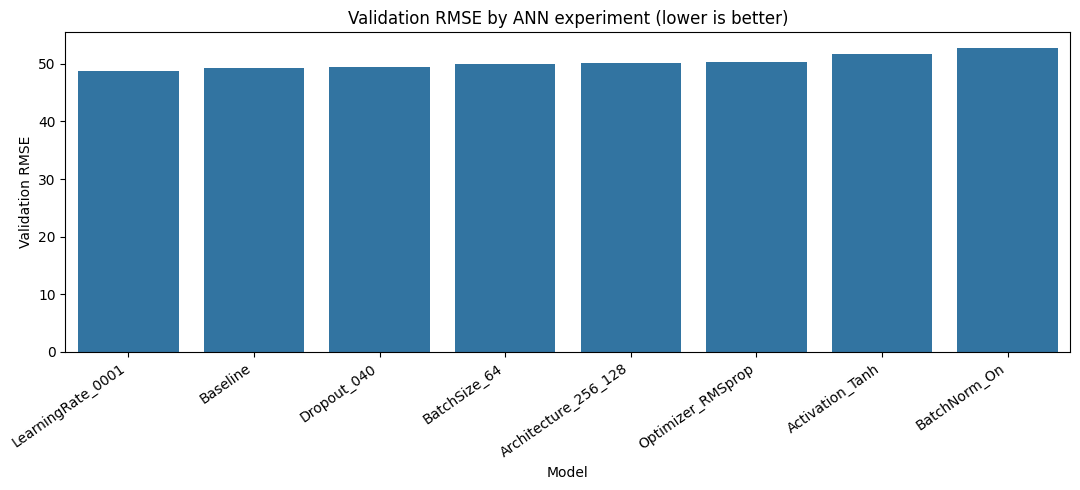

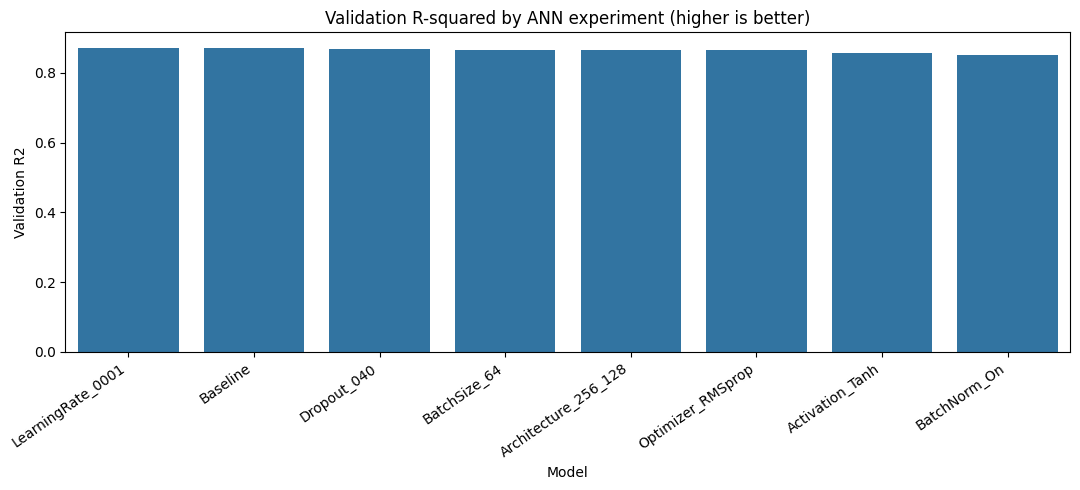

In [22]:
plt.figure(figsize=(11, 5))
sns.barplot(data=results_df, x="Model", y="Validation RMSE")
plt.title("Validation RMSE by ANN experiment (lower is better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
sns.barplot(data=results_df, x="Model", y="Validation R2")
plt.title("Validation R-squared by ANN experiment (higher is better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

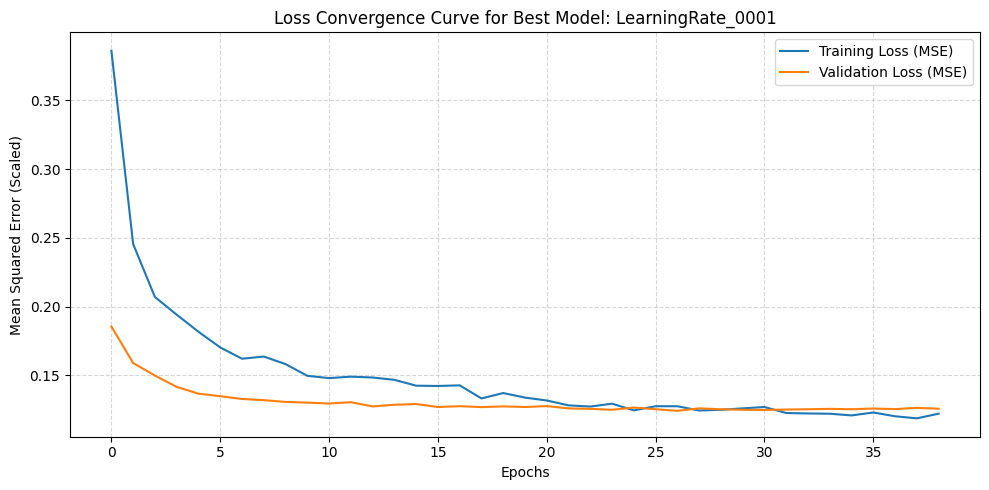

In [23]:
# Plot training and validation loss curves safely by checking if experiment_histories exists
import matplotlib.pyplot as plt

if 'experiment_histories' in globals() and 'best_model_name' in globals():
    best_history = experiment_histories[best_model_name]

    plt.figure(figsize=(10, 5))
    plt.plot(best_history.history['loss'], label='Training Loss (MSE)')
    plt.plot(best_history.history['val_loss'], label='Validation Loss (MSE)')
    plt.title(f'Loss Convergence Curve for Best Model: {best_model_name}')
    plt.xlabel('Epochs')
    plt.ylabel('Mean Squared Error (Scaled)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("Please run Section 9 (cell 82a1b99a) first to train the models and generate 'experiment_histories'.")

## 10. Final evaluation on the held-out test set

In [24]:
# The test set is evaluated only after selecting the model on validation RMSE.
test_scaled = best_model.predict(X_test, verbose=0)
test_predictions = target_scaler.inverse_transform(test_scaled).ravel()

def regression_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "R2": r2_score(actual, predicted)
    }

ann_test_metrics = regression_metrics(y_test, test_predictions)
persistence_test_metrics = regression_metrics(y_test, persistence_test)

comparison = pd.DataFrame([
    {"Model": "Persistence baseline (tomorrow = latest AQI)", **persistence_test_metrics},
    {"Model": f"SmartAir ANN ({best_model_name})", **ann_test_metrics}
])
display(comparison)

rmse_improvement = (
    (persistence_test_metrics["RMSE"] - ann_test_metrics["RMSE"])
    / persistence_test_metrics["RMSE"] * 100
)
print(f"ANN RMSE improvement over persistence baseline: {rmse_improvement:.2f}%")

,Model,MAE,MSE,RMSE,R2
0,Persistence baseline (tomorrow = latest AQI),28.556911,2251.975586,47.454985,0.835650
1,SmartAir ANN (LearningRate_0001),29.401371,1669.837891,40.863650,0.878135


ANN RMSE improvement over persistence baseline: 13.89%


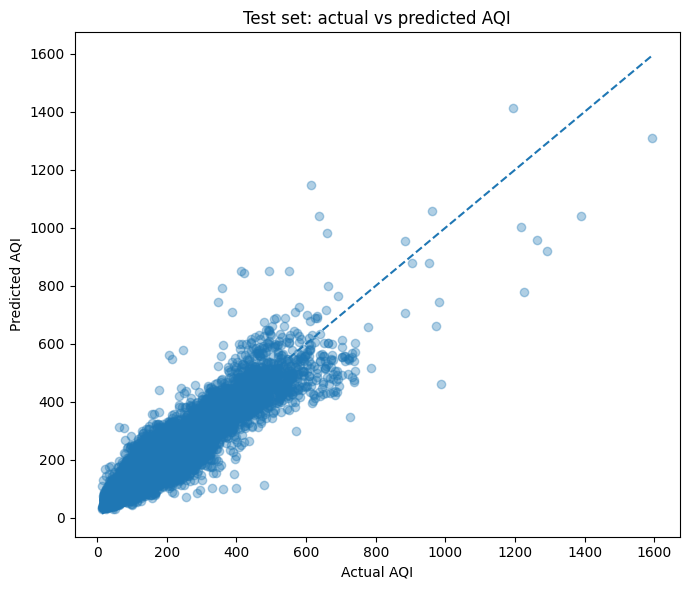

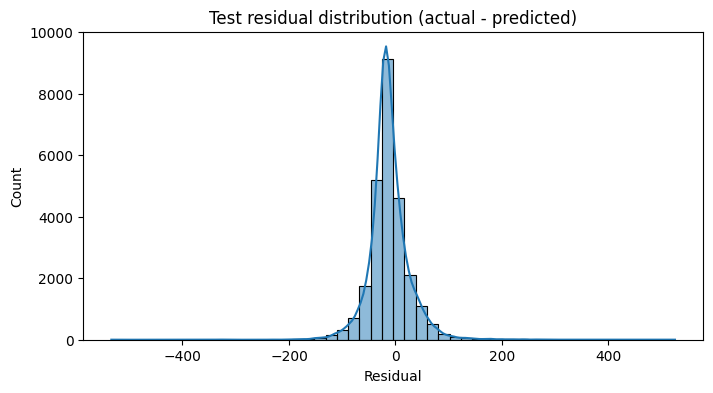

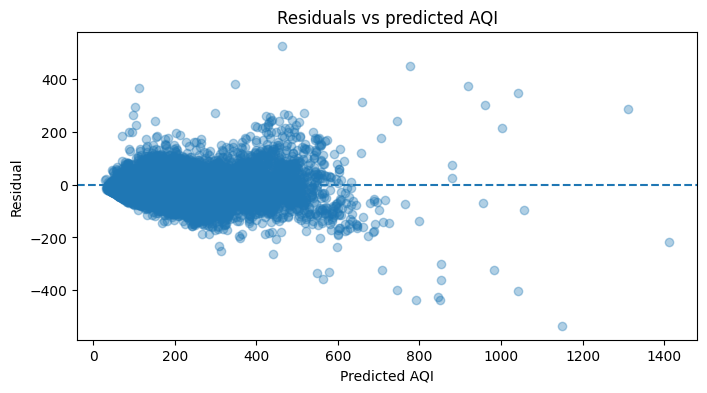

In [25]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, test_predictions, alpha=0.35)
lo = min(float(np.min(y_test)), float(np.min(test_predictions)))
hi = max(float(np.max(y_test)), float(np.max(test_predictions)))
plt.plot([lo, hi], [lo, hi], "--")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Test set: actual vs predicted AQI")
plt.tight_layout()
plt.show()

residuals = y_test - test_predictions
plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Test residual distribution (actual - predicted)")
plt.xlabel("Residual")
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(test_predictions, residuals, alpha=0.35)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted AQI")
plt.ylabel("Residual")
plt.title("Residuals vs predicted AQI")
plt.show()

In [26]:
# Optional error breakdown by broad AQI bands (descriptive analysis).
# Bands are used only for reporting; they are not model inputs.
def aqi_band(v):
    if v <= 50: return "Good (0-50)"
    if v <= 100: return "Satisfactory (51-100)"
    if v <= 200: return "Moderate (101-200)"
    if v <= 300: return "Poor (201-300)"
    if v <= 400: return "Very Poor (301-400)"
    return "Severe (>400)"

error_analysis = pd.DataFrame({
    "Actual AQI": y_test,
    "Predicted AQI": test_predictions,
    "Absolute Error": np.abs(y_test - test_predictions)
})
error_analysis["Actual AQI Band"] = error_analysis["Actual AQI"].map(aqi_band)
display(error_analysis.groupby("Actual AQI Band").agg(
    Samples=("Absolute Error", "size"),
    MAE=("Absolute Error", "mean"),
    Mean_Actual_AQI=("Actual AQI", "mean"),
    Mean_Predicted_AQI=("Predicted AQI", "mean")
).round(2))

,Samples,MAE,Mean_Actual_AQI,Mean_Predicted_AQI
Actual AQI Band,,,,
Good (0-50),2163,26.059999,39.200001,65.199997
Moderate (101-200),8633,27.910000,137.320007,155.289993
Poor (201-300),3026,35.230000,247.619995,243.000000
Satisfactory (51-100),8400,23.530001,75.779999,98.080002
Severe (>400),1125,66.209999,491.279999,463.910004
Very Poor (301-400),2790,33.110001,338.920013,327.679993


## 11. Save model, preprocessing objects, metrics, and predictions

In [27]:
OUTPUT_DIR = "smartair_output"
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
RESULT_DIR = os.path.join(OUTPUT_DIR, "results")
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

best_model.save(os.path.join(MODEL_DIR, "best_model.keras"))
joblib.dump(imputer, os.path.join(MODEL_DIR, "imputer.pkl"))
joblib.dump(scaler, os.path.join(MODEL_DIR, "feature_scaler.pkl"))
joblib.dump(target_scaler, os.path.join(MODEL_DIR, "target_scaler.pkl"))

preprocessing_info = {
    "lookback_days": LOOKBACK,
    "selected_pollutants": selected_pollutants,
    "excluded_pollutants": excluded_pollutants,
    "numeric_features": numeric_features,
    "feature_names": feature_names,
    "training_stations": train_stations,
    "train_end_date": str(train_end_date.date()),
    "validation_end_date": str(val_end_date.date()),
    "best_model_name": best_model_name,
    "best_config": best_config
}
joblib.dump(preprocessing_info, os.path.join(MODEL_DIR, "preprocessing_info.pkl"))

results_df.to_csv(os.path.join(RESULT_DIR, "validation_experiments.csv"), index=False)
comparison.to_csv(os.path.join(RESULT_DIR, "test_metrics.csv"), index=False)

prediction_output = pd.DataFrame({
    "StationId": station_parts["test"],
    "Target Date": test_target_dates,
    "Actual AQI": y_test,
    "Predicted AQI": test_predictions,
    "Persistence Prediction": persistence_test,
    "Absolute Error": np.abs(y_test - test_predictions)
})
prediction_output.to_csv(os.path.join(RESULT_DIR, "test_predictions.csv"), index=False)

print("Saved files under:", OUTPUT_DIR)

Saved files under: smartair_output


## 12. Final project summary and limitations

In [28]:
print("=" * 65)
print("SMARTAIR — FINAL SUMMARY")
print("=" * 65)
print(f"Original rows: {len(df):,}")
print(f"Cleaned rows:  {len(data):,}")
print(f"Stations:      {data['StationId'].nunique():,}")
print(f"Lookback:      {LOOKBACK} consecutive days")
print("Target:        next-day AQI")
print(f"Features:      {len(feature_names)} total ({len(numeric_features)} numeric + station indicators)")
print("\nForecasting samples:")
print(f"Train: {len(y_train):,}")
print(f"Validation: {len(y_val):,}")
print(f"Test: {len(y_test):,}")
print(f"Selected model: {best_model_name}")
print("\nHeld-out test metrics:")
for metric, value in ann_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nInterpretation:")
print("- MAE is the average absolute AQI prediction error in AQI points.")
print("- RMSE penalizes larger errors more strongly than MAE.")
print("- R2 measures explained variance relative to predicting the test-set mean.")
print("- Compare the ANN with the persistence baseline; a neural network is useful only if it improves on a simple baseline.")

print("\nLimitations:")
print("- This is a historical-data prototype, not a certified public-health warning system.")
print("- Performance may vary by station, season, sensor quality, and future pollution patterns.")
print("- The model requires seven consecutive days of historical station data.")
print("- It has not been validated on completely unseen stations or an independent external dataset.")
print("- A single chronological test period does not guarantee future real-world performance.")

SMARTAIR — FINAL SUMMARY
Original rows: 108,035
Cleaned rows:  87,025
Stations:      109
Lookback:      7 consecutive days
Target:        next-day AQI
Features:      91 total (16 numeric + station indicators)

Forecasting samples:
Train: 28,196
Validation: 20,815
Test: 26,137
Selected model: LearningRate_0001

Held-out test metrics:
MAE: 29.4014
MSE: 1669.8379
RMSE: 40.8636
R2: 0.8781

Interpretation:
- MAE is the average absolute AQI prediction error in AQI points.
- RMSE penalizes larger errors more strongly than MAE.
- R2 measures explained variance relative to predicting the test-set mean.
- Compare the ANN with the persistence baseline; a neural network is useful only if it improves on a simple baseline.

Limitations:
- This is a historical-data prototype, not a certified public-health warning system.
- Performance may vary by station, season, sensor quality, and future pollution patterns.
- The model requires seven consecutive days of historical station data.
- It has not been va